In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
df = pd.read_csv("/content/Besant_Student_Pass_Prediction - Besant_Student_Pass_Prediction.csv")
print(df)

     Study_Hours_Per_Day  Attendance_Percentage  Previous_Exam_Score  \
0                    5.8                     82                   47   
1                    8.1                     91                   70   
2                    7.1                     72                   39   
3                    2.4                     83                   38   
4                    3.1                     61                   87   
..                   ...                    ...                  ...   
195                  6.3                     92                   36   
196                  0.7                     54                   52   
197                  3.1                     89                   90   
198                  8.5                     80                   84   
199                  5.1                     70                   67   

     Assignments_Completed  Passed  
0                       10       1  
1                        3       1  
2                       

In [6]:
df.head()

,Study_Hours_Per_Day,Attendance_Percentage,Previous_Exam_Score,Assignments_Completed,Passed
0,5.8,82,47,10,1
1,8.1,91,70,3,1
2,7.1,72,39,9,1
3,2.4,83,38,10,0
4,3.1,61,87,6,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Study_Hours_Per_Day    200 non-null    float64
 1   Attendance_Percentage  200 non-null    int64  
 2   Previous_Exam_Score    200 non-null    int64  
 3   Assignments_Completed  200 non-null    int64  
 4   Passed                 200 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 7.9 KB


In [8]:
df.describe()

,Study_Hours_Per_Day,Attendance_Percentage,Previous_Exam_Score,Assignments_Completed,Passed
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,4.772500,75.440000,60.995000,5.090000,0.540000
std,2.487556,14.219613,21.278365,3.078847,0.499648
min,0.500000,50.000000,26.000000,0.000000,0.000000
25%,2.600000,62.750000,42.000000,3.000000,0.000000
50%,4.900000,77.000000,59.500000,5.000000,1.000000
75%,6.925000,88.000000,80.250000,8.000000,1.000000
max,9.000000,100.000000,95.000000,10.000000,1.000000


In [9]:
df.shape

(200, 5)

In [10]:
df.isnull().sum()

,0
Study_Hours_Per_Day,0
Attendance_Percentage,0
Previous_Exam_Score,0
Assignments_Completed,0
Passed,0


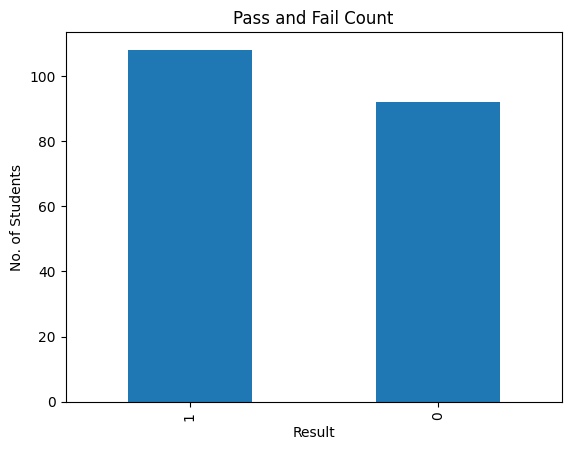

In [11]:
df['Passed'].value_counts().plot(kind="bar")
plt.title("Pass and Fail Count")
plt.xlabel("Result")
plt.ylabel("No. of Students")
plt.show()

In [12]:
X = df.drop("Passed", axis=1)
y = df["Passed"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [14]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [15]:
y_pred = model.predict(X_test)
print(y_pred)

[0 1 1 0 0 0 1 0 1 1 1 0 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 0 0 1 0
 0 1 1]


In [16]:
print("Accuracy_score:",accuracy_score(y_test, y_pred))

Accuracy_score: 0.825


In [17]:
print("Confusion Matrix\n",confusion_matrix(y_test, y_pred))

Confusion Matrix
 [[15  3]
 [ 4 18]]


In [18]:
print("Classification Report\n",classification_report(y_test, y_pred))

Classification Report
               precision    recall  f1-score   support

           0       0.79      0.83      0.81        18
           1       0.86      0.82      0.84        22

    accuracy                           0.82        40
   macro avg       0.82      0.83      0.82        40
weighted avg       0.83      0.82      0.83        40



In [19]:
import pickle
with open("student_model.pkl", "wb") as file:
  pickle.dump(model, file)